# FINAL NOTEBOOK 01 — Compulsory CHIRPS laboratory validation
### PH3043 · Sri Lanka Rainfall Research · Six stations · 1981–2000

**Study objective:** independently reproduce the lab-sheet compulsory scientific tasks *before* comparing complex or physics-informed models. The target is gauge rainfall; CHIRPS v2 is the compulsory baseline, CHIRPS v3 RNL (is a high-resolution rainfall dataset used for climate monitoring, rainfall analysis, drought assessment, and hydrological research.) is an optional but useful matched comparison.

**Research questions addressed here**

1. **RQ1 / H1:** How do raw CHIRPS v2 and v3 daily amounts and wet-day skill compare at all six stations? H₀: there is no expected difference in predictive loss between products.
2. **RQ2:** Can a **simple training-only correction** improve CHIRPS estimates on withheld dates? H₀: the expected corrected-minus-raw error improvement is zero.
3. **Compulsory monthly/seasonal comparison:** What do complete-month totals and seasonal patterns reveal? Detailed pentad/multiscale tests follow in Final Notebook 02.

**Split used here:** training **1981–1990**, independent laboratory validation **1991–1994**, historical test **1995–2000**. This is ~71/29 train/validation within the 1981–1994 development interval, close to the laboratory's suggested chronological 70/30 split. The historical test is **not evaluated in Notebook 01**, since earlier exploratory notebooks have inspected it.

**Important:** This is *retrospective CHIRPS calibration*, not an operational next-day forecast. Same-day satellite data may be used to correct the corresponding day's rainfall, but gauge targets from withheld dates must never enter fitted coefficients.



## 0 · Setup and data paths

The existing source dataset `Ground_CHIRPS_V2_V3_Paired_1981_2000.xls` is **CSV-formatted text despite its `.xls` extension**. `pandas.read_csv`, *not* `read_excel`, is correct. Keep the source file unchanged.

The loader looks in your project’s `data/processed/`, then the project root, then `/mnt/data` when running in this environment. If it cannot locate the dataset, set `DATA_PATH` below. Output directories are created only for newly generated analyses.

In [5]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats
from sklearn.linear_model import LinearRegression
from IPython.display import display

plt.rcParams.update({'figure.dpi': 115, 'savefig.dpi': 220, 'font.size': 10, 'axes.grid': True, 'grid.alpha': 0.25})

PROJECT_ROOT = Path.cwd()
for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / 'data').is_dir() and (candidate / 'notebooks').is_dir():
        PROJECT_ROOT = candidate
        break

DATA_PATH = None  # Optional: Path('/your/own/path/Ground_CHIRPS_V2_V3_Paired_1981_2000.xls')
FILENAME = "Ground_CHIRPS_V2_V3_Paired_1981_2000.csv"
search_paths = [PROJECT_ROOT/'data'/'processed'/FILENAME, PROJECT_ROOT/FILENAME,
                Path.cwd()/FILENAME, Path('/mnt/data')/FILENAME]
if DATA_PATH is None:
    DATA_PATH = next((p for p in search_paths if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError(f'Cannot locate {FILENAME}. Set DATA_PATH in this cell. Searched: {search_paths}')

OUTPUT = PROJECT_ROOT / 'results' / 'Final_01_Lab_Validation' / 'run_001'
if OUTPUT.exists():
    n = 2
    while (OUTPUT.parent/f'run_{n:03d}').exists(): n += 1
    OUTPUT = OUTPUT.parent/f'run_{n:03d}'
FIGDIR, TABDIR = OUTPUT/'figures', OUTPUT/'tables'
FIGDIR.mkdir(parents=True, exist_ok=False)
TABDIR.mkdir(parents=True, exist_ok=False)

TRAIN = ('1981-01-01', '1990-12-31')
VALID = ('1991-01-01', '1994-12-31')
TEST = ('1995-01-01', '2000-12-31')  # stated for the protocol; NOT scored in this notebook
WET_THRESHOLD_MM = 1.0
HEAVY_THRESHOLD_MM = 25.0
STATIONS = ['Badulla', 'Colombo', 'Galle', 'Kandy', 'Nuwaraeliya', 'Puttalam']
PRODUCTS = {'CHIRPS v2': 'CHIRPS_mm', 'CHIRPS v3 RNL': 'CHIRPS_V3_mm'}
print('Dataset:', DATA_PATH)
print('Project root:', PROJECT_ROOT)
print('Output folder:', OUTPUT)

Dataset: C:\Users\Asini Perera\CP Lab 1\CP Lab 2\Sri Lanka Rain Fall Reserach\data\processed\Ground_CHIRPS_V2_V3_Paired_1981_2000.csv
Project root: C:\Users\Asini Perera\CP Lab 1\CP Lab 2\Sri Lanka Rain Fall Reserach
Output folder: C:\Users\Asini Perera\CP Lab 1\CP Lab 2\Sri Lanka Rain Fall Reserach\results\Final_01_Lab_Validation\run_001


## 1 · Load, validate schema, and examine missingness

**Why?** The scientific unit of comparison is one *matched station × calendar day*. We must check date uniqueness, rainfall units, nonnegative values, trace codes and missing days. Never convert missing rainfall observations to zero.

**Caution about trace observations:** The existing processed file flags traces (`QC_Flag == 'Trace'`) and encodes them as `Rainfall_mm=0.0`; this is an inherited, documented convention, not direct evidence that the physical rainfall amount was exactly zero. We **retain the trace indicator** and will separately show a sensitivity calculation excluding traces. The 1 mm/day wet threshold is not sensitive to this zero-versus-submillimetre trace distinction when traces are genuinely below 1 mm.

In [7]:
def load_paired_data(path):
    d = pd.read_csv(path)
    mandatory = ['Date', 'Station', 'Rainfall_mm', 'CHIRPS_mm', 'CHIRPS_V3_mm', 'QC_Flag']
    missing = set(mandatory) - set(d.columns)
    if missing: raise ValueError(f'Missing required columns: {sorted(missing)}')
    d['Date'] = pd.to_datetime(d['Date'], errors='raise')
    d['Station'] = d['Station'].astype(str).str.strip().replace({'Nuwara Eliya':'Nuwaraeliya'})
    for c in ['Rainfall_mm', 'CHIRPS_mm', 'CHIRPS_V3_mm']:
        d[c] = pd.to_numeric(d[c], errors='coerce')
    if d.duplicated(['Station','Date']).any():
        raise ValueError('Duplicate station/date keys detected: resolve BEFORE scoring.')
    if (d[['Rainfall_mm','CHIRPS_mm','CHIRPS_V3_mm']] < 0).any().any():
        raise ValueError('Negative rainfall encountered. Recheck missing-value conventions.')
    return d.sort_values(['Station','Date']).reset_index(drop=True)

def select_period(d, period):
    return d[d['Date'].between(pd.Timestamp(period[0]), pd.Timestamp(period[1]))].copy()

raw = load_paired_data(DATA_PATH)
print('Rows in already-paired source:', len(raw))
print('Range:', raw.Date.min().date(), 'to', raw.Date.max().date())
print('QC flag counts:')
display(raw.QC_Flag.value_counts(dropna=False).rename_axis('QC flag').to_frame('Rows'))

# IMPORTANT: enumerate expected calendar keys; the processed source already omits missing gauge days.
full_days = pd.date_range('1981-01-01','2000-12-31',freq='D')
calendar = pd.MultiIndex.from_product([STATIONS, full_days], names=['Station','Date']).to_frame(index=False)
qc = calendar.merge(raw[['Station','Date','Rainfall_mm','CHIRPS_mm','CHIRPS_V3_mm','QC_Flag']],
                    on=['Station','Date'], how='left', validate='one_to_one', indicator=True)
qc['is_paired_both'] = (qc['_merge']=='both') & qc[['Rainfall_mm','CHIRPS_mm','CHIRPS_V3_mm']].notna().all(axis=1)
coverage = (qc.groupby('Station',as_index=False).agg(
    expected_days=('Date','size'),
    paired_days=('is_paired_both','sum'),
    trace_days=('QC_Flag',lambda s: (s=='Trace').sum())))
coverage['missing_days'] = coverage['expected_days']-coverage['paired_days']
coverage['paired_percent'] = 100*coverage['paired_days']/coverage['expected_days']
display(coverage)
coverage.to_csv(TABDIR/'table01_data_coverage.csv',index=False)
assert coverage['expected_days'].eq(7305).all(), 'Unexpected study calendar length'
assert int(coverage['paired_days'].sum()) == int(qc.is_paired_both.sum())

Rows in already-paired source: 43737
Range: 1981-01-01 to 2000-12-31
QC flag counts:


,Rows
QC flag,
Valid,43182
Trace,555


,Station,expected_days,paired_days,trace_days,missing_days,paired_percent
0,Badulla,7305,7300,550,5,99.931554
1,Colombo,7305,7279,0,26,99.644079
2,Galle,7305,7291,0,14,99.808350
3,Kandy,7305,7296,3,9,99.876797
4,Nuwaraeliya,7305,7278,2,27,99.630390
5,Puttalam,7305,7293,0,12,99.835729


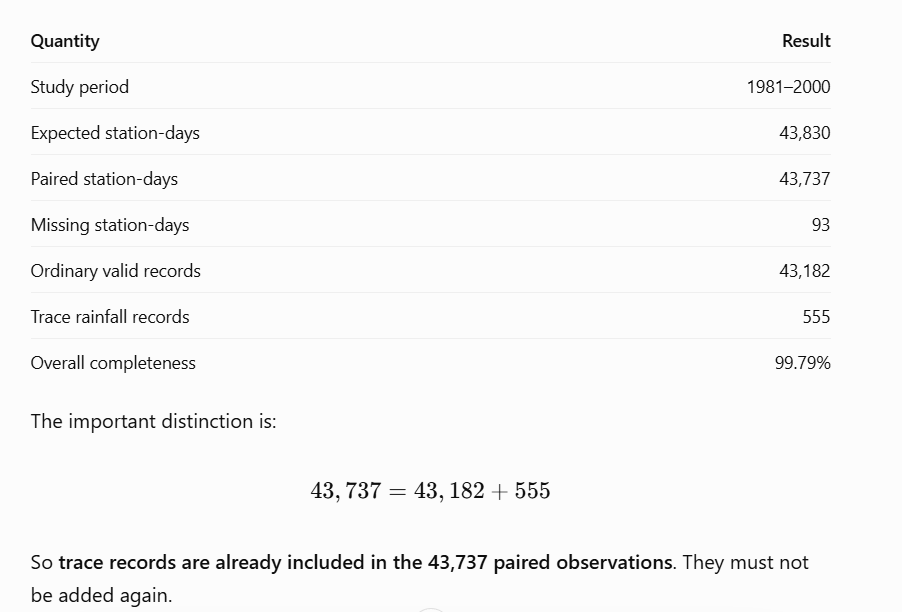

The dataset has high temporal completeness, making it suitable for daily rainfall evaluation. However, the unusually large number of trace records at Badulla (550) should be investigated as a possible difference in observational recording or preprocessing.
The study utilized daily ground-based rainfall observations from six meteorological stations in Sri Lanka, together with CHIRPS version 2 (v2) and CHIRPS version 3 Reanalysis (v3 RNL) daily precipitation estimates for the period 1981–2000. The paired dataset comprised 43,737 valid station–date observations, representing 99.79% of the 43,830 possible station-days. Of these, 43,182 observations were classified as valid and 555 as trace rainfall. Missing observations were excluded rather than replaced with zero. Notably, 550 of the 555 trace records originated from Badulla, highlighting a potential difference in observational recording or data preprocessing that warrants further investigation through sensitivity analysis. The resulting dataset was used to evaluate the accuracy of CHIRPS v2 and v3 RNL against ground observations.

### Reusable plotting functions (define once, call throughout the project)

**Scientific graphics rules:** units in labels, matched dates, titles naming the station/product, sample count when appropriate, informative captions in the final report, and **no double-counting dates**. The functions return Matplotlib `(fig, ax)` objects so you can further customize them, and optionally save publication-resolution PNG/PDF figures.

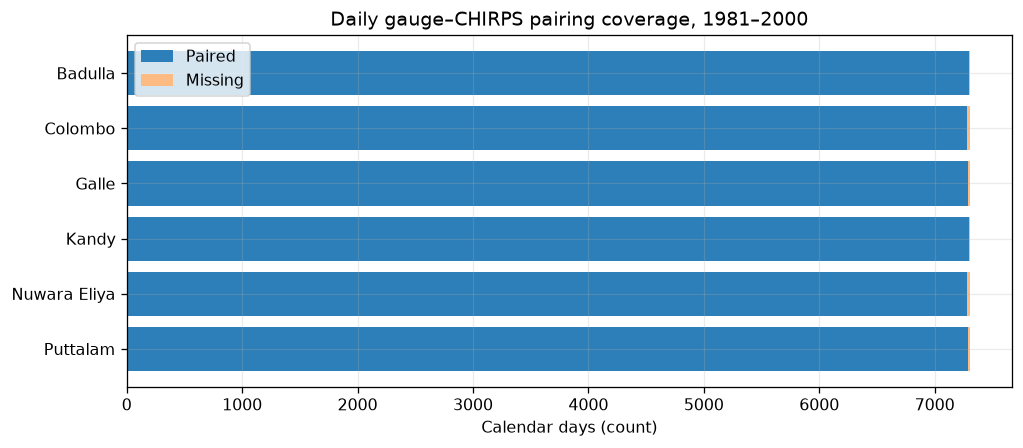

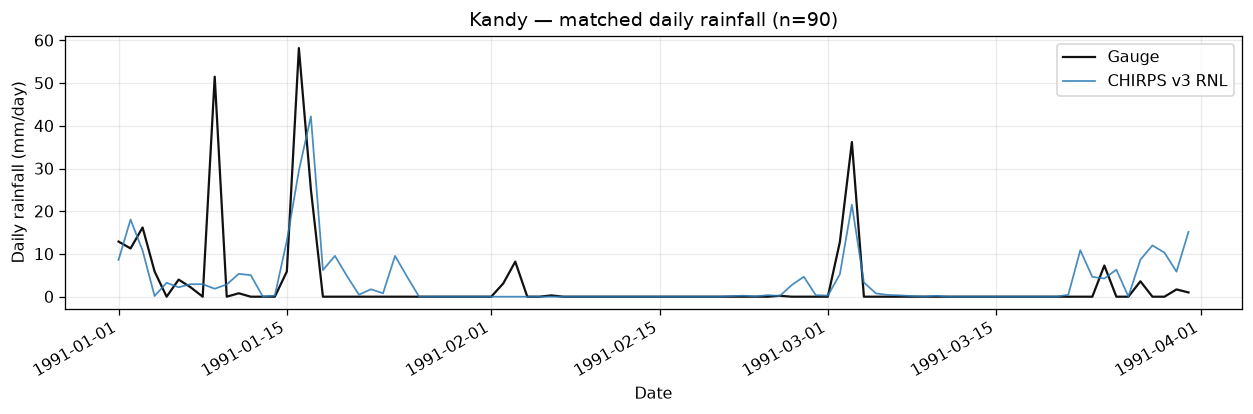

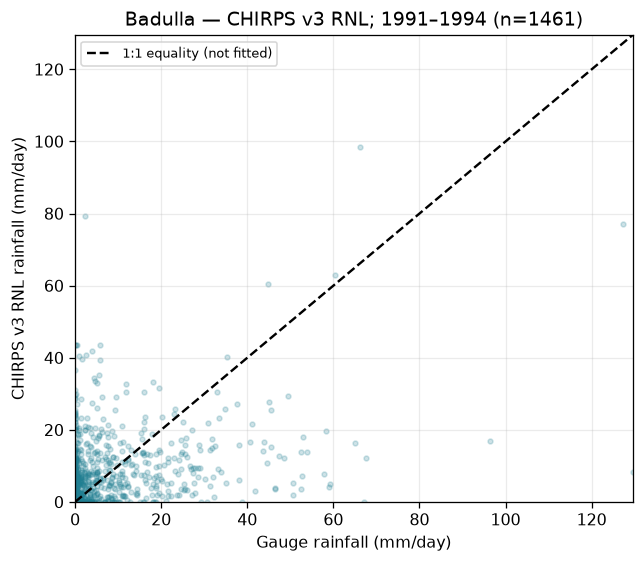

In [9]:
def save_figure(fig, stem, folder=FIGDIR):
    """Save both raster (PNG) and vector (PDF) copies; never silently overwrite an existing file."""
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    for suffix in ('.png','.pdf'):
        target = folder/(stem+suffix)
        if target.exists(): raise FileExistsError(target)
        fig.savefig(target,bbox_inches='tight')
    return fig

def plot_coverage(data, save_as=None):
    fig, ax = plt.subplots(figsize=(9,4))
    x = np.arange(len(data))
    ax.barh(x,data['paired_days'],label='Paired',color='#2c7fb8')
    ax.barh(x,data['missing_days'],left=data['paired_days'],label='Missing',color='#fdbb84')
    ax.set_yticks(x, data.Station.str.replace('Nuwaraeliya','Nuwara Eliya'))
    ax.invert_yaxis(); ax.set_xlabel('Calendar days (count)')
    ax.set_title('Daily gauge–CHIRPS pairing coverage, 1981–2000')
    ax.legend(); fig.tight_layout()
    if save_as: save_figure(fig,save_as)
    return fig,ax

def plot_timeseries(d,station,product='CHIRPS v3 RNL',start='1991-01-01',end='1991-02-28',save_as=None):
    x = d[(d.Station==station)&d.Date.between(start,end)].sort_values('Date')
    if x.empty: raise ValueError('No paired observations in requested interval')
    fig,ax=plt.subplots(figsize=(11,3.7))
    ax.plot(x.Date,x.Rainfall_mm,label='Gauge',lw=1.4, color='#111111')
    ax.plot(x.Date,x[PRODUCTS[product]],label=product,lw=1.1,alpha=.85,color='#2878b5')
    ax.set_ylabel('Daily rainfall (mm/day)');ax.set_xlabel('Date')
    ax.set_title(f'{station} — matched daily rainfall (n={len(x)})')
    ax.legend(); fig.autofmt_xdate();fig.tight_layout()
    if save_as:save_figure(fig,save_as)
    return fig,ax

def plot_scatter(d,station,product='CHIRPS v3 RNL',period=VALID,save_as=None):
    x=select_period(d[d.Station==station],period)[['Rainfall_mm',PRODUCTS[product]]].dropna()
    fig,ax=plt.subplots(figsize=(5.7,5))
    ax.scatter(x.Rainfall_mm,x[PRODUCTS[product]],s=9,alpha=.22,color='#207f92',rasterized=True)
    mx=max(x.max().max(),1)
    ax.plot([0,mx],[0,mx],'k--',label='1:1 equality (not fitted)')
    ax.set(xlabel='Gauge rainfall (mm/day)',ylabel=f'{product} rainfall (mm/day)',
           title=f'{station} — {product}; {period[0][:4]}–{period[1][:4]} (n={len(x)})',xlim=(0,mx),ylim=(0,mx))
    ax.legend(fontsize=8);fig.tight_layout()
    if save_as:save_figure(fig,save_as)
    return fig,ax

def plot_monthly(dmonthly,station,product='CHIRPS v3 RNL',save_as=None):
    x=dmonthly[dmonthly.Station==station].sort_values('Month')
    fig,ax=plt.subplots(figsize=(10,3.6))
    ax.plot(x.Month,x.Gauge_total_mm,label='Gauge monthly total',lw=1.5,color='#222222')
    ax.plot(x.Month,x[product+'_total_mm'],label=product,lw=1.2,color='#2a76aa')
    ax.set(xlabel='Month',ylabel='Complete-month rainfall total (mm/month)',
           title=f'{station}: complete monthly totals (n={len(x)} months)')
    ax.legend();fig.autofmt_xdate();fig.tight_layout()
    if save_as:save_figure(fig,save_as)
    return fig,ax

def plot_rmse_dotplot(score_table,products=('CHIRPS v2','CHIRPS v3 RNL'),save_as=None):
    t=score_table[score_table.Product.isin(products)]
    stations=[s for s in STATIONS if s in t.Station.unique()]
    fig,ax=plt.subplots(figsize=(8.5,4.7))
    for i,p in enumerate(products):
        sub=t[t.Product==p].set_index('Station').reindex(stations)
        ax.scatter(sub.RMSE_mm_day,np.arange(len(stations))+(i-.5)*.16,label=p,s=65)
    ax.set_yticks(range(len(stations)),[s.replace('Nuwaraeliya','Nuwara Eliya') for s in stations])
    ax.invert_yaxis();ax.set_xlabel('Daily RMSE (mm/day; lower is better)')
    ax.set_title('RMSE dot plot — descriptive point estimates (no CI shown)')
    ax.legend();fig.tight_layout()
    if save_as:save_figure(fig,save_as)
    return fig,ax

fig,ax=plot_coverage(coverage,'fig01_data_coverage');plt.show()
fig,ax=plot_timeseries(raw,'Kandy',start='1991-01-01',end='1991-03-31',save_as='fig02_kandy_daily_timeseries');plt.show()
fig,ax=plot_scatter(raw,'Badulla',save_as='fig03_badulla_v3_scatter');plt.show()

## 2 · Raw daily baseline statistics

For matched observed gauge rainfall $G_i$ and CHIRPS estimate $S_i$, with $N$ valid pairs:

$$\operatorname{Bias}=\frac1N\sum_i(S_i-G_i),\quad
\operatorname{MAE}=\frac1N\sum_i|S_i-G_i|,\quad
\operatorname{RMSE}=\sqrt{\frac1N\sum_i(S_i-G_i)^2}. $$

Pearson $r$ describes **linear association**, not agreement. We also compute Spearman $\rho$ (monotonic association with tied values). Correlation may be undefined for constant input. Do not rank rainfall products using correlation alone.

**Lab requirement:** calculate the statistics for v2. **Extension:** on exactly the same station/date pairs, repeat for v3. Main comparisons below report **1991–1994 validation**, not the historical test years.
 These metrics measure different characteristics:
- Bias tells us whether rainfall is overestimated or underestimated on average.
- MAE measures average absolute error.
- RMSE penalizes large errors more heavily.
- Pearson measures linear association.
- Spearman measures monotonic association based on ranks.


,Station,Product,period_start,period_end,n,mean_gauge_mm_day,mean_est_mm_day,Bias_mm_day,MAE_mm_day,RMSE_mm_day,Pearson_r,Spearman_rho
0,Badulla,CHIRPS v2,1991-01-01,1994-12-31,1461,4.508,4.592,0.083,5.355,11.305,0.467,0.404
1,Badulla,CHIRPS v3 RNL,1991-01-01,1994-12-31,1461,4.508,4.829,0.320,5.243,10.820,0.413,0.548
2,Colombo,CHIRPS v2,1991-01-01,1994-12-31,1460,6.705,5.612,-1.093,7.397,18.541,0.429,0.436
3,Colombo,CHIRPS v3 RNL,1991-01-01,1994-12-31,1460,6.705,6.202,-0.503,6.729,17.957,0.461,0.566
4,Galle,CHIRPS v2,1991-01-01,1994-12-31,1461,6.482,5.822,-0.660,7.718,17.609,0.387,0.393
5,Galle,CHIRPS v3 RNL,1991-01-01,1994-12-31,1461,6.482,6.774,0.292,7.072,15.822,0.418,0.532
6,Kandy,CHIRPS v2,1991-01-01,1994-12-31,1461,4.978,4.988,0.010,6.291,12.665,0.373,0.344
7,Kandy,CHIRPS v3 RNL,1991-01-01,1994-12-31,1461,4.978,5.201,0.223,5.458,10.569,0.440,0.520
8,Nuwaraeliya,CHIRPS v2,1991-01-01,1994-12-31,1458,5.534,5.548,0.013,6.805,13.430,0.357,0.345
9,Nuwaraeliya,CHIRPS v3 RNL,1991-01-01,1994-12-31,1458,5.534,5.162,-0.372,5.229,10.606,0.435,0.602


FileExistsError: C:\Users\Asini Perera\CP Lab 1\CP Lab 2\Sri Lanka Rain Fall Reserach\results\Final_01_Lab_Validation\run_001\figures\fig04_validation_v2_v3_RMSE_dotplot.png

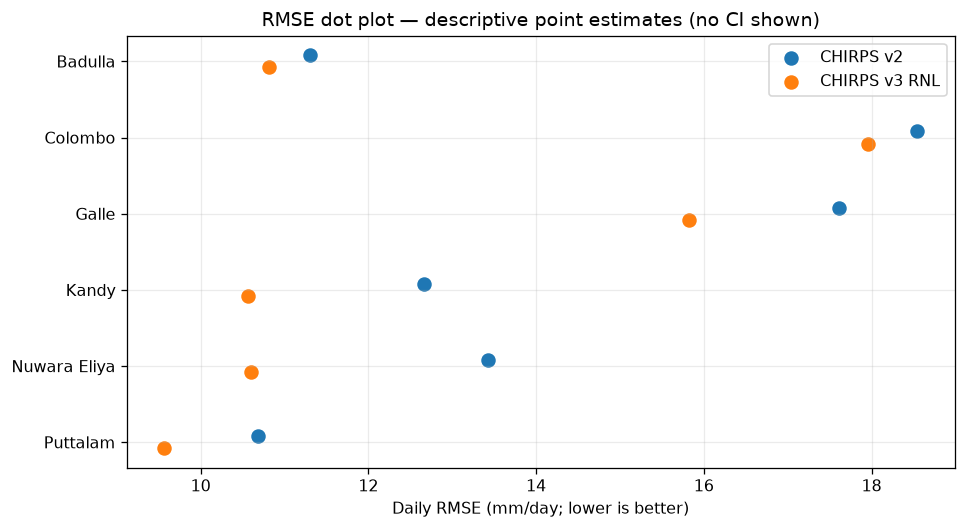

In [36]:
#calculating validating statistics
def paired_scores(observed,estimated):
    o=np.asarray(observed,float);e=np.asarray(estimated,float)
    ok=np.isfinite(o)&np.isfinite(e)&(o>=0)&(e>=0)
    o=o[ok];e=e[ok];n=len(o)
    if n<2: return dict(n=n,mean_gauge_mm_day=np.nan,mean_est_mm_day=np.nan,
                        Bias_mm_day=np.nan,MAE_mm_day=np.nan,RMSE_mm_day=np.nan,
                        Pearson_r=np.nan,Spearman_rho=np.nan)
    pearson = stats.pearsonr(o,e).statistic if np.std(o)>0 and np.std(e)>0 else np.nan
    spearman = stats.spearmanr(o,e).statistic if len(np.unique(o))>1 and len(np.unique(e))>1 else np.nan
    error=e-o
    return dict(n=n,mean_gauge_mm_day=o.mean(),mean_est_mm_day=e.mean(),
                Bias_mm_day=error.mean(),MAE_mm_day=np.abs(error).mean(),
                RMSE_mm_day=np.sqrt(np.mean(error**2)),
                Pearson_r=pearson,Spearman_rho=spearman)

def score_products(d,period=VALID):
    x=select_period(d,period)
    rows=[]
    for station in STATIONS:
        station_x=x[x.Station==station]
        for p,col in PRODUCTS.items():
            scores=paired_scores(station_x.Rainfall_mm,station_x[col])
            rows.append(dict(Station=station,Product=p,period_start=period[0],period_end=period[1],**scores))
    return pd.DataFrame(rows)

validation_daily=score_products(raw)
display(validation_daily.round(3))
validation_daily.to_csv(TABDIR/'table02_validation_raw_daily_scores.csv',index=False)
fig,ax=plot_rmse_dotplot(validation_daily,save_as='fig04_validation_v2_v3_RMSE_dotplot');plt.show()

# Scientific pair check: each product must have the same n for each station on the validation dates.
assert validation_daily.groupby('Station').n.nunique().eq(1).all()

### H1: Are v2 and v3 errors different on the same dates?

The comparison is paired, not independent: subtract **per-day losses** for the same station and date. We report sample-size and descriptive differences here. Because rainfall and errors are temporally dependent, *naive daily independence t-tests are not our final inference*. Year-block bootstrap uncertainty and repeated-fold model comparisons are reserved for Final Notebook 02/06.

In [13]:
def version_difference_table(scores):
    p=scores.pivot(index='Station',columns='Product',values=['RMSE_mm_day','MAE_mm_day','Pearson_r'])
    res=pd.DataFrame(index=p.index)
    res['RMSE_v2_mm_day']=p['RMSE_mm_day']['CHIRPS v2']
    res['RMSE_v3_mm_day']=p['RMSE_mm_day']['CHIRPS v3 RNL']
    res['v3_RMSE_improvement_percent']=100*(res.RMSE_v2_mm_day-res.RMSE_v3_mm_day)/res.RMSE_v2_mm_day
    res['Pearson_r_v2']=p['Pearson_r']['CHIRPS v2']
    res['Pearson_r_v3']=p['Pearson_r']['CHIRPS v3 RNL']
    return res.reset_index()

version_comparison=version_difference_table(validation_daily)
display(version_comparison.round(3))
version_comparison.to_csv(TABDIR/'table03_validation_v2_v3_difference.csv',index=False)
#Theese results are also from 1991-1994

,Station,RMSE_v2_mm_day,RMSE_v3_mm_day,v3_RMSE_improvement_percent,Pearson_r_v2,Pearson_r_v3
0,Badulla,11.305,10.820,4.288,0.467,0.413
1,Colombo,18.541,17.957,3.146,0.429,0.461
2,Galle,17.609,15.822,10.148,0.387,0.418
3,Kandy,12.665,10.569,16.545,0.373,0.440
4,Nuwaraeliya,13.430,10.606,21.030,0.357,0.435
5,Puttalam,10.690,9.567,10.504,0.320,0.427


The descriptive results support improved v3 daily RMSE at all six stations. We have not yet quantified the statistical uncertainty of those improvements. Because pearson correlationship decrease

## 3 · Wet-day occurrence statistics (compulsory)
Research question: Can CHIRPS correctly distinguish rainy days from non-rainy days?
Define a **wet day** as rainfall $\geq 1\ \mathrm{mm/day}$. Count:

- **Hit (H):** both gauge and estimate are wet.(POD measures the fraction of observed rainy days detected)
- **Miss (M):** gauge wet, estimate dry.
- **False alarm (F):** gauge dry, estimate wet.(AR measures the fraction of predicted rainy days that were false alarms)
- **Correct negative (CN):** both dry. (CSI combines hits, misses and false alarms.)

$$\mathrm{POD}=\frac H{H+M},\quad
\mathrm{FAR}=\frac F{H+F},\quad
\mathrm{CSI}=\frac H{H+M+F}.$$

POD is detection sensitivity; FAR is the fraction of predicted wet days that were false alarms. CSI penalizes both misses and false alarms. All three are dimensionless; counts are days.

,Station,Product,n,threshold_mm_day,Hits,Misses,False_alarms,Correct_negatives,POD,FAR,CSI
0,Badulla,CHIRPS v2,1461,1.0,236,251,161,813,0.485,0.406,0.364
1,Badulla,CHIRPS v3 RNL,1461,1.0,405,82,348,626,0.832,0.462,0.485
2,Colombo,CHIRPS v2,1460,1.0,284,266,160,750,0.516,0.360,0.400
3,Colombo,CHIRPS v3 RNL,1460,1.0,489,61,442,468,0.889,0.475,0.493
4,Galle,CHIRPS v2,1461,1.0,239,379,83,760,0.387,0.258,0.341
5,Galle,CHIRPS v3 RNL,1461,1.0,490,128,368,475,0.793,0.429,0.497
6,Kandy,CHIRPS v2,1461,1.0,241,346,134,740,0.411,0.357,0.334
7,Kandy,CHIRPS v3 RNL,1461,1.0,476,111,338,536,0.811,0.415,0.515
8,Nuwaraeliya,CHIRPS v2,1458,1.0,282,406,130,640,0.410,0.316,0.345
9,Nuwaraeliya,CHIRPS v3 RNL,1458,1.0,591,97,316,454,0.859,0.348,0.589


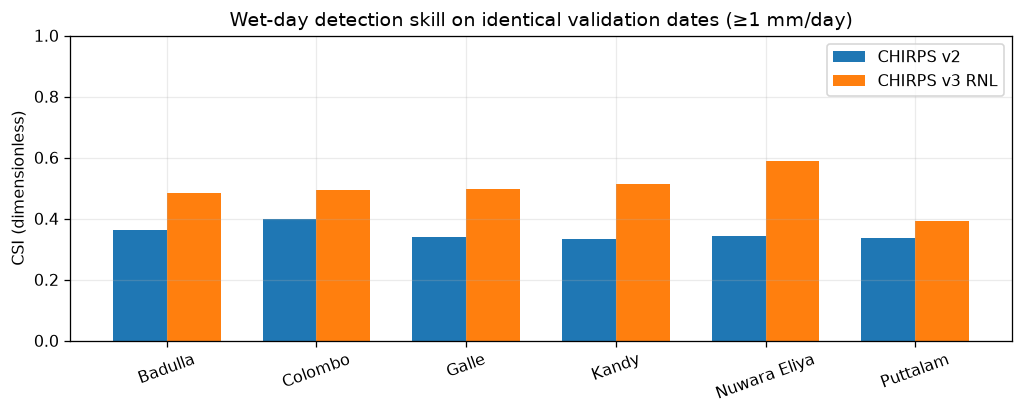

In [15]:
def wetday_scores(observed,estimated,threshold_mm=WET_THRESHOLD_MM):
    o=np.asarray(observed,float);e=np.asarray(estimated,float)
    ok=np.isfinite(o)&np.isfinite(e)
    gw=o[ok]>=threshold_mm; sw=e[ok]>=threshold_mm
    H=int(np.sum(gw&sw));M=int(np.sum(gw&~sw))
    F=int(np.sum(~gw&sw));CN=int(np.sum(~gw&~sw))
    def ratio(n,d):return n/d if d else np.nan
    return dict(n=H+M+F+CN,threshold_mm_day=threshold_mm,
                Hits=H,Misses=M,False_alarms=F,Correct_negatives=CN,
                POD=ratio(H,H+M),FAR=ratio(F,H+F),CSI=ratio(H,H+M+F))

def wetday_table(d,period=VALID):
    rows=[]
    x=select_period(d,period)
    for station in STATIONS:
        s=x[x.Station==station]
        for product,col in PRODUCTS.items():
            rows.append(dict(Station=station,Product=product,**wetday_scores(s.Rainfall_mm,s[col])))
    return pd.DataFrame(rows)

validation_wet=wetday_table(raw)
display(validation_wet.round(3))
validation_wet.to_csv(TABDIR/'table04_validation_wetday_skill.csv',index=False)

def plot_wetday_metrics(wet,metric='CSI',save_as=None):
    p=wet.pivot(index='Station',columns='Product',values=metric).reindex(STATIONS)
    fig,ax=plt.subplots(figsize=(9,3.7))
    xs=np.arange(len(p));width=.36
    for i,product in enumerate(p.columns):
        ax.bar(xs+(i-.5)*width,p[product],width=width,label=product)
    ax.set_xticks(xs,[s.replace('Nuwaraeliya','Nuwara Eliya') for s in p.index],rotation=20)
    ax.set_ylim(0,1);ax.set_ylabel(f'{metric} (dimensionless)')
    ax.set_title('Wet-day detection skill on identical validation dates (≥1 mm/day)')
    ax.legend();fig.tight_layout()
    if save_as:save_figure(fig,save_as)
    return fig,ax
fig,ax=plot_wetday_metrics(validation_wet,save_as='fig05_validation_wetday_CSI');plt.show()

v3 detects considerably more observed rainy days, and CSI improves at all six stations. But v3 also has more false alarms, so the improvement is not unqualified.

For example, at Colombo:
- v2: 284 hits and 160 false alarms.
- v3: 489 hits and 442 false alarms.
Scientific conclusion: CHIRPS v3 improves rainfall detection sensitivity, but this comes with increased false rainfall predictions.

## 4 · Complete-month totals and seasonal behaviour (compulsory)

**Do not sum only available days and call the result a full monthly total.** A complete month is retained only if every calendar day has a matched gauge and satellite reading. Missing days remain missing; they are not filled with zeros. We compute monthly total in **mm/month** (rainfall depth over the month), not in mm/day.

Monthly Pearson correlation describes the association between complete-month totals. It cannot by itself establish that daily rain timing is correct.

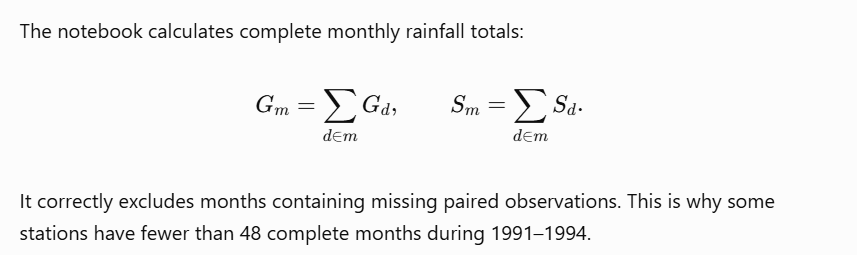

,Station,complete_months
0,Badulla,48
1,Colombo,47
2,Galle,48
3,Kandy,48
4,Nuwaraeliya,45
5,Puttalam,47


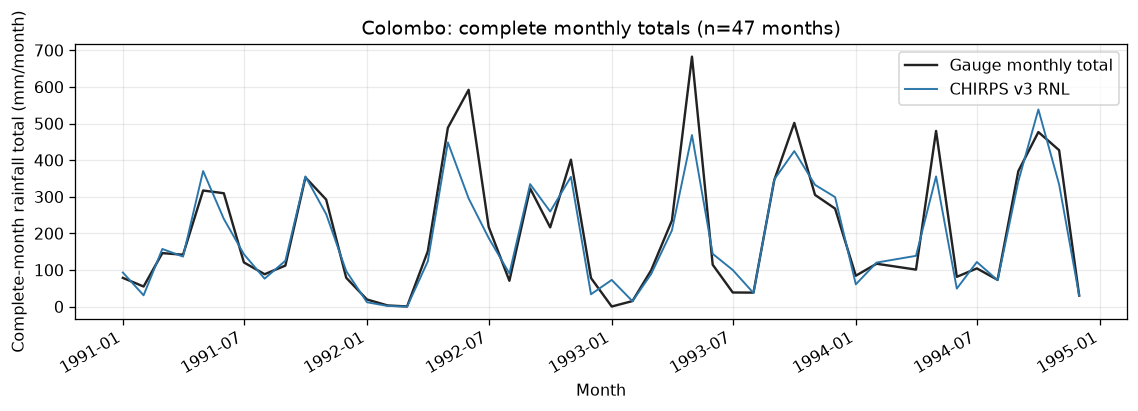

,Station,Product,n_complete_months,Gauge_monthly_mean_mm,Estimated_monthly_mean_mm,Bias_mm_month,MAE_mm_month,RMSE_mm_month,Pearson_r,Spearman_rho
0,Badulla,CHIRPS v2,48,137.227,139.762,2.535,52.844,73.860,0.811,0.818
1,Badulla,CHIRPS v3 RNL,48,137.227,146.982,9.755,42.241,60.301,0.874,0.844
2,Colombo,CHIRPS v2,47,205.483,172.703,-32.780,55.378,87.651,0.886,0.883
3,Colombo,CHIRPS v3 RNL,47,205.483,190.110,-15.373,39.012,66.126,0.935,0.950
4,Galle,CHIRPS v2,48,197.298,177.215,-20.083,62.091,98.912,0.823,0.822
5,Galle,CHIRPS v3 RNL,48,197.298,206.185,8.887,51.706,73.395,0.909,0.932
6,Kandy,CHIRPS v2,48,151.531,151.832,0.301,62.097,94.232,0.736,0.730
7,Kandy,CHIRPS v3 RNL,48,151.531,158.309,6.778,31.371,40.821,0.935,0.915
8,Nuwaraeliya,CHIRPS v2,45,168.891,164.249,-4.642,60.610,78.265,0.747,0.746
9,Nuwaraeliya,CHIRPS v3 RNL,45,168.891,156.542,-12.349,36.897,45.776,0.926,0.917


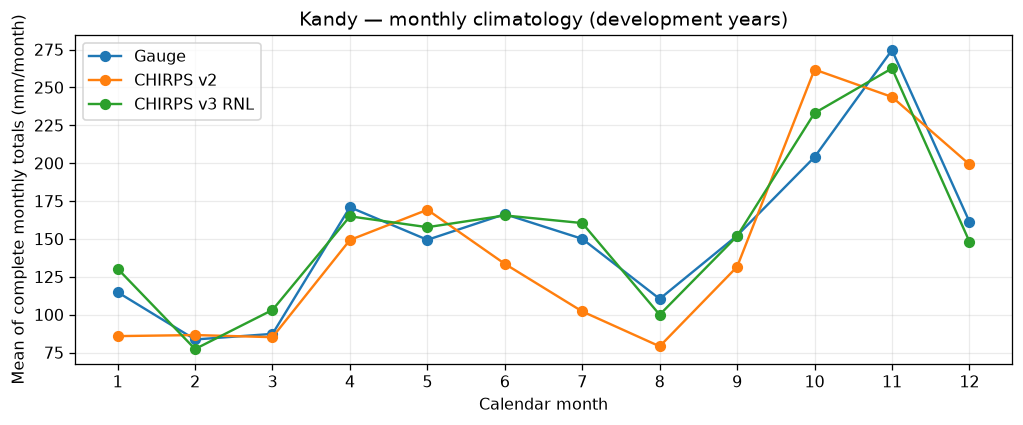

In [17]:
def make_complete_months(d,products=PRODUCTS):
    x=d[['Station','Date','Rainfall_mm',*products.values()]].copy()
    x['Month']=x.Date.dt.to_period('M').dt.to_timestamp()
    cols=['Rainfall_mm',*products.values()]
    a=x.groupby(['Station','Month'],as_index=False).agg(
        observed_days=('Date','nunique'),
        **{f'{col}_total':(col,'sum') for col in cols},
        **{f'{col}_valid':(col,'count') for col in cols})
    a['days_expected']=a.Month.dt.days_in_month
    complete=(a.observed_days==a.days_expected)
    for col in cols: complete &= a[f'{col}_valid']==a.days_expected
    a=a[complete].copy()
    names={'Rainfall_mm_total':'Gauge_total_mm'}
    names.update({f'{col}_total':f'{p}_total_mm' for p,col in products.items()})
    return a.rename(columns=names).sort_values(['Station','Month']).reset_index(drop=True)

monthly=make_complete_months(raw)
monthly_dev=monthly[monthly.Month.between('1991-01-01','1994-12-01')].copy()
monthly_coverage=monthly_dev.groupby('Station',as_index=False).agg(complete_months=('Month','size'))
display(monthly_coverage)
monthly_coverage.to_csv(TABDIR/'table05_validation_complete_month_coverage.csv',index=False)
assert monthly_dev.groupby('Station').size().le(48).all()
fig,ax=plot_monthly(monthly_dev,'Colombo',save_as='fig06_colombo_complete_month_timeseries');plt.show()

def monthly_scores(m,d_products=('CHIRPS v2','CHIRPS v3 RNL')):
    rows=[]
    for station in STATIONS:
        x=m[m.Station==station]
        for prod in d_products:
            obs=x.Gauge_total_mm.to_numpy(dtype=float)
            est=x[prod+'_total_mm'].to_numpy(dtype=float)
            sc=paired_scores(obs,est)
            rows.append({'Station':station,'Product':prod,'n_complete_months':len(x),
                         'Gauge_monthly_mean_mm':np.mean(obs),'Estimated_monthly_mean_mm':np.mean(est),
                         'Bias_mm_month':np.mean(est-obs),'MAE_mm_month':np.mean(abs(est-obs)),
                         'RMSE_mm_month':np.sqrt(np.mean((est-obs)**2)),
                         'Pearson_r':sc['Pearson_r'],'Spearman_rho':sc['Spearman_rho']})
    return pd.DataFrame(rows)

validation_monthly=monthly_scores(monthly_dev)
display(validation_monthly.round(3))
validation_monthly.to_csv(TABDIR/'table06_validation_monthly_totals_scores.csv',index=False)

def plot_monthly_climatology(monthly_data,station,save_as=None):
    x=monthly_data[monthly_data.Station==station].copy()
    x['calendar_month']=x.Month.dt.month
    means=x.groupby('calendar_month')[['Gauge_total_mm','CHIRPS v2_total_mm','CHIRPS v3 RNL_total_mm']].mean()
    fig,ax=plt.subplots(figsize=(9,3.8))
    for column,label in [('Gauge_total_mm','Gauge'),('CHIRPS v2_total_mm','CHIRPS v2'),
                         ('CHIRPS v3 RNL_total_mm','CHIRPS v3 RNL')]:
        ax.plot(means.index,means[column],marker='o',label=label)
    ax.set(xticks=list(range(1,13)),xlabel='Calendar month',
           ylabel='Mean of complete monthly totals (mm/month)',
           title=f'{station} — monthly climatology (development years)')
    ax.legend();fig.tight_layout()
    if save_as:save_figure(fig,save_as)
    return fig,ax

monthly_train=monthly[monthly.Month.between('1981-01-01','1990-12-01')]
fig,ax=plot_monthly_climatology(monthly_train,'Kandy',save_as='fig07_kandy_training_monthly_climatology');plt.show()

A daily mismatch may occur because CHIRPS allocates rainfall to a different day or misestimates an individual event. When daily rainfall is accumulated into a month, some positive and negative daily errors may cancel.

Monthly totals also emphasize broader seasonal variability rather than exact daily event timing.

However, aggregation does not guarantee improved correlation for every dataset. Here, we have observed the improvement empirically.
CHIRPS v3 reproduces monthly rainfall variability substantially better than individual daily rainfall variability, but monthly correlation alone does not establish accurate accumulated rainfall amounts.

linear correction has a positive intercept at every station. Consequently, it can predict rain even when CHIRPS originally predicts zero rainfall.

At Badulla, the corrected model predicts at least: Gd^ = 1.8412 mm/day  by intercept even when aw CHIRPS v3 reports zero.

Because the wet-day threshold is 1 mm/day, the corrected model classifies every Badulla validation day as rainy.

The notebook confirms this:
- POD becomes 1.000.
- False alarms increase to 974.
- CSI falls from 0.485 to 0.333.
  That means the model detects every actual rainy day, but also declares every dry day rainy.

This is a scientifically important failure of the simple correction.

## 5 · Simple calibration with **training-only** coefficients (compulsory)

We use an interpretable station-specific linear model fitted to **1981–1990 only**:

$$\widehat G_d=\max(0,a+bS_d),\qquad (a,b)=\arg\min_{a,b}\sum_{d\in \mathrm{TRAIN}}[G_d-(a+bS_d)]^2.$$

Clipping guarantees nonnegative rainfall. This baseline is intentionally simple; it does **not** solve wet-day thresholding, intensity bias or extreme rainfall by design. We compare uncorrected and corrected satellite values on **exactly the same 1991–1994 validation dates**.

**Important:** Fitting the linear coefficients separately for v2 and v3 is fair; choosing whichever version/model performs best from the 1995–2000 test would not be fair. We show both here without declaring a final winner.
The parameters are fitted using 1981–1990 only, and evaluated on 1991–1994.

In [19]:
def fit_linear_calibration(training,station,product='CHIRPS v3 RNL'):
    s=training[training.Station==station]
    x=s[[PRODUCTS[product]]].to_numpy(float)
    y=s.Rainfall_mm.to_numpy(float)
    valid=np.isfinite(x[:,0])&np.isfinite(y)
    if valid.sum()<30:raise ValueError('Insufficient training pairs')
    model=LinearRegression().fit(x[valid],y[valid])
    return {'station':station,'product':product,'a':float(model.intercept_),
            'b':float(model.coef_[0]),'train_n':int(valid.sum()),'model':model}

def apply_linear_calibration(fit,values):
    v=np.asarray(values,dtype=float)
    # The model is never fitted on these values or on their corresponding targets.
    return np.maximum(0,fit['a']+fit['b']*v)

train=select_period(raw,TRAIN)
validation=select_period(raw,VALID)
fitted=[];rows=[];prediction_rows=[]
for station in STATIONS:
    s=validation[validation.Station==station]
    for product,col in PRODUCTS.items():
        fit=fit_linear_calibration(train,station,product)
        fitted.append({k:v for k,v in fit.items() if k!='model'})
        raw_score=paired_scores(s.Rainfall_mm,s[col])
        predicted=apply_linear_calibration(fit,s[col])
        corr_score=paired_scores(s.Rainfall_mm,predicted)
        rows.append({'Station':station,'Product':product,'validation_n':len(s),
                     'Raw_RMSE_mm_day':raw_score['RMSE_mm_day'],
                     'Corrected_RMSE_mm_day':corr_score['RMSE_mm_day'],
                     'RMSE_improvement_percent':100*(raw_score['RMSE_mm_day']-corr_score['RMSE_mm_day'])/raw_score['RMSE_mm_day'],
                     'Raw_MAE_mm_day':raw_score['MAE_mm_day'],
                     'Corrected_MAE_mm_day':corr_score['MAE_mm_day'],
                     'Raw_Bias_mm_day':raw_score['Bias_mm_day'],
                     'Corrected_Bias_mm_day':corr_score['Bias_mm_day'],
                     'Raw_Pearson_r':raw_score['Pearson_r'],
                     'Corrected_Pearson_r':corr_score['Pearson_r']})
        prediction_rows.append(pd.DataFrame({'Date':s.Date.to_numpy(),'Station':station,'Product':product,
                                            'Gauge_mm_day':s.Rainfall_mm.to_numpy(),
                                            'Raw_mm_day':s[col].to_numpy(),
                                            'Corrected_mm_day':predicted}))

fits_df=pd.DataFrame(fitted)
comparison=pd.DataFrame(rows)
calibration_predictions=pd.concat(prediction_rows,ignore_index=True)
display(fits_df.drop(columns=['model'],errors='ignore').round(4))
display(comparison.round(3))
fits_df.to_csv(TABDIR/'table07_training_only_linear_coefficients.csv',index=False)
comparison.to_csv(TABDIR/'table08_validation_simple_correction_comparison.csv',index=False)
calibration_predictions.to_csv(TABDIR/'validation_daily_predictions.csv',index=False)
assert (calibration_predictions.Date<='1994-12-31').all()

,station,product,a,b,train_n
0,Badulla,CHIRPS v2,2.7794,0.4805,3648
1,Badulla,CHIRPS v3 RNL,1.8412,0.6259,3648
2,Colombo,CHIRPS v2,2.7752,0.6104,3628
3,Colombo,CHIRPS v3 RNL,1.2026,0.7555,3628
4,Galle,CHIRPS v2,3.8067,0.4074,3638
5,Galle,CHIRPS v3 RNL,2.0799,0.6239,3638
6,Kandy,CHIRPS v2,3.3367,0.3423,3645
7,Kandy,CHIRPS v3 RNL,2.0392,0.5766,3645
8,Nuwaraeliya,CHIRPS v2,3.3687,0.3212,3640
9,Nuwaraeliya,CHIRPS v3 RNL,1.7666,0.6509,3640


,Station,Product,validation_n,Raw_RMSE_mm_day,Corrected_RMSE_mm_day,RMSE_improvement_percent,Raw_MAE_mm_day,Corrected_MAE_mm_day,Raw_Bias_mm_day,Corrected_Bias_mm_day,Raw_Pearson_r,Corrected_Pearson_r
0,Badulla,CHIRPS v2,1461,11.305,9.849,12.876,5.355,5.689,0.083,0.477,0.467,0.467
1,Badulla,CHIRPS v3 RNL,1461,10.820,10.160,6.096,5.243,5.547,0.320,0.355,0.413,0.413
2,Colombo,CHIRPS v2,1460,18.541,18.355,1.004,7.397,7.804,-1.093,-0.504,0.429,0.429
3,Colombo,CHIRPS v3 RNL,1460,17.957,18.101,-0.801,6.729,6.898,-0.503,-0.817,0.461,0.461
4,Galle,CHIRPS v2,1461,17.609,15.528,11.815,7.718,7.530,-0.660,-0.304,0.387,0.387
5,Galle,CHIRPS v3 RNL,1461,15.822,15.286,3.385,7.072,6.992,0.292,-0.176,0.418,0.418
6,Kandy,CHIRPS v2,1461,12.665,10.025,20.844,6.291,6.051,0.010,0.066,0.373,0.373
7,Kandy,CHIRPS v3 RNL,1461,10.569,9.711,8.122,5.458,5.565,0.223,0.060,0.440,0.440
8,Nuwaraeliya,CHIRPS v2,1458,13.430,10.685,20.438,6.805,6.048,0.013,-0.384,0.357,0.357
9,Nuwaraeliya,CHIRPS v3 RNL,1458,10.606,10.297,2.907,5.229,5.379,-0.372,-0.408,0.435,0.435


In [55]:
# ============================================================
# LINEAR CALIBRATION — IMPROVEMENT SUMMARY
# Validation period: 1991–1994
# ============================================================

improvement = comparison.copy()

# Percentage improvement (positive = better)
improvement["MAE_improvement_percent"] = (
    100 * (
        improvement["Raw_MAE_mm_day"]
        - improvement["Corrected_MAE_mm_day"]
    ) / improvement["Raw_MAE_mm_day"]
)

# Absolute error reduction (positive = better)
improvement["RMSE_reduction_mm_day"] = (
    improvement["Raw_RMSE_mm_day"]
    - improvement["Corrected_RMSE_mm_day"]
)

improvement["MAE_reduction_mm_day"] = (
    improvement["Raw_MAE_mm_day"]
    - improvement["Corrected_MAE_mm_day"]
)

# Clear indication of whether calibration worked
improvement["Result"] = np.select(
    [
        improvement["RMSE_improvement_percent"] > 0.01,
        improvement["RMSE_improvement_percent"] < -0.01
    ],
    [
        "Improved",
        "Worsened"
    ],
    default="No meaningful numerical change"
)

summary_columns = [
    "Station",
    "Product",
    "Raw_RMSE_mm_day",
    "Corrected_RMSE_mm_day",
    "RMSE_reduction_mm_day",
    "RMSE_improvement_percent",
    "Raw_MAE_mm_day",
    "Corrected_MAE_mm_day",
    "MAE_improvement_percent",
    "Result"
]

improvement_summary = improvement[summary_columns]

display(
    improvement_summary
    .sort_values(["Product", "Station"])
    .round(3)
)

# Save for your report
improvement_summary.to_csv(
    TABDIR / "table09_linear_calibration_improvements.csv",
    index=False
)
#RMSE imporvment is consiered ans results improve or worsned

,Station,Product,Raw_RMSE_mm_day,Corrected_RMSE_mm_day,RMSE_reduction_mm_day,RMSE_improvement_percent,Raw_MAE_mm_day,Corrected_MAE_mm_day,MAE_improvement_percent,Result
0,Badulla,CHIRPS v2,11.305,9.849,1.456,12.876,5.355,5.689,-6.232,Improved
2,Colombo,CHIRPS v2,18.541,18.355,0.186,1.004,7.397,7.804,-5.509,Improved
4,Galle,CHIRPS v2,17.609,15.528,2.080,11.815,7.718,7.530,2.436,Improved
6,Kandy,CHIRPS v2,12.665,10.025,2.640,20.844,6.291,6.051,3.812,Improved
8,Nuwaraeliya,CHIRPS v2,13.430,10.685,2.745,20.438,6.805,6.048,11.124,Improved
10,Puttalam,CHIRPS v2,10.690,9.993,0.696,6.515,3.915,4.429,-13.126,Improved
1,Badulla,CHIRPS v3 RNL,10.820,10.160,0.660,6.096,5.243,5.547,-5.801,Improved
3,Colombo,CHIRPS v3 RNL,17.957,18.101,-0.144,-0.801,6.729,6.898,-2.525,Worsened
5,Galle,CHIRPS v3 RNL,15.822,15.286,0.536,3.385,7.072,6.992,1.130,Improved
7,Kandy,CHIRPS v3 RNL,10.569,9.711,0.858,8.122,5.458,5.565,-1.953,Improved


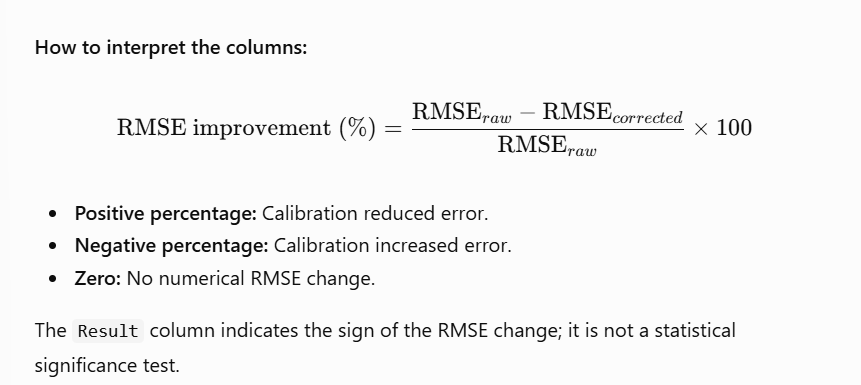

In [59]:
def plot_calibration_improvement(
    improvement_summary,
    product="CHIRPS v3 RNL",
    save_as=None
):
    data = improvement_summary[
        improvement_summary["Product"] == product
    ].copy()

    fig, ax = plt.subplots(figsize=(9, 5))

    values = data["RMSE_improvement_percent"].to_numpy()

    colors = [
        "seagreen" if v >= 0 else "firebrick"
        for v in values
    ]

    ax.barh(
        data["Station"],
        values,
        color=colors,
        alpha=0.85
    )

    ax.axvline(0, color="black", linewidth=1)

    ax.set_xlabel("RMSE improvement relative to raw CHIRPS (%)")
    ax.set_ylabel("Meteorological station")
    ax.set_title(f"Effect of linear calibration — {product}\n"
                 "Validation: 1991–1994")

    for i, value in enumerate(values):
        ax.annotate(
            f"{value:+.2f}%",
            xy=(value, i),
            xytext=(5 if value >= 0 else -5, 0),
            textcoords="offset points",
            ha="left" if value >= 0 else "right",
            va="center",
            fontsize=10
        )

    ax.grid(axis="x", alpha=0.2)
    fig.tight_layout()

    if save_as is not None:
        fig.savefig(FIGDIR / f"{save_as}.png",
                    dpi=300, bbox_inches="tight")

    return fig, ax

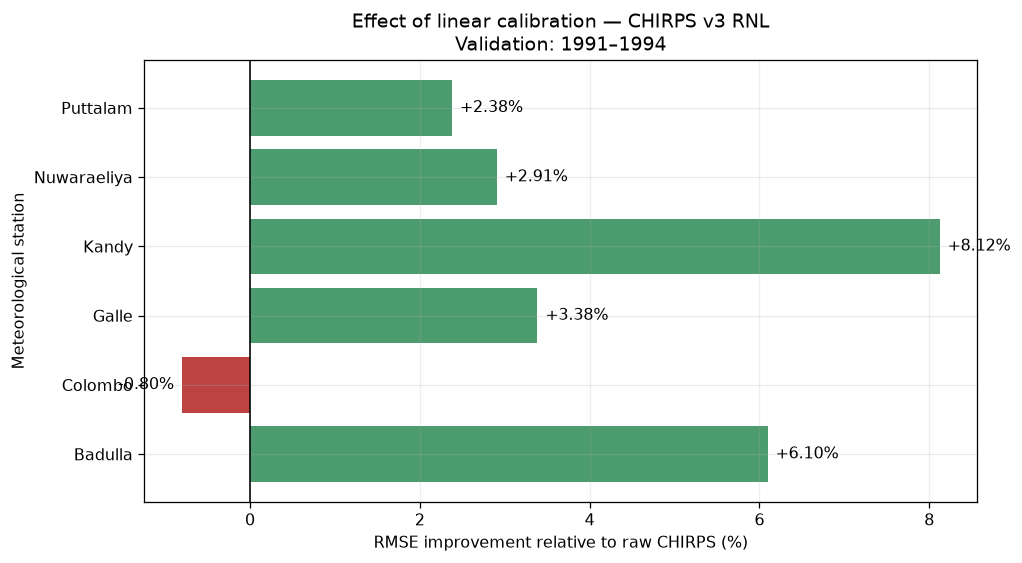

In [61]:
fig, ax = plot_calibration_improvement(
    improvement_summary,
    product="CHIRPS v3 RNL",
    save_as="fig_linear_calibration_improvement_v3"
)

plt.show()

### Plot uncorrected versus corrected estimates

This chart is a *paired comparison on validation days*. A negative RMSE improvement percentage means calibration **worsened** the validation RMSE. The conclusion should mention failures, not only successes.

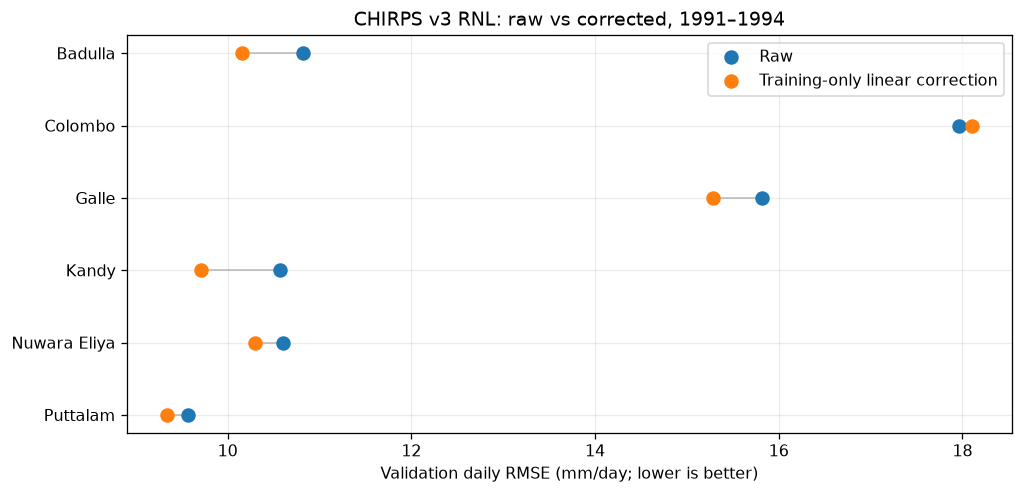

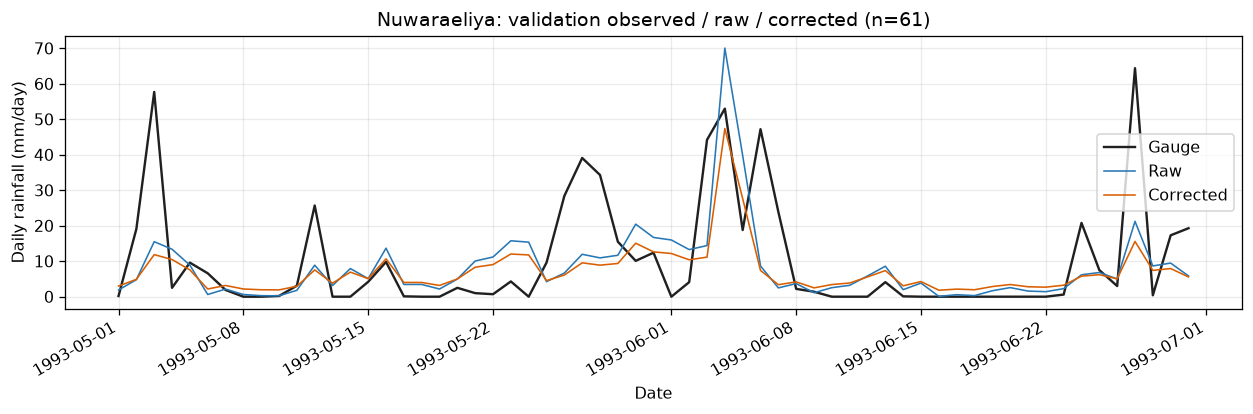

In [21]:
def plot_calibration_dotplot(comparison,product='CHIRPS v3 RNL',save_as=None):
    x=comparison[comparison.Product==product].set_index('Station').reindex(STATIONS)
    y=np.arange(len(STATIONS))
    fig,ax=plt.subplots(figsize=(9,4.4))
    ax.hlines(y,x.Raw_RMSE_mm_day,x.Corrected_RMSE_mm_day,alpha=.5,color='gray',lw=1)
    ax.scatter(x.Raw_RMSE_mm_day,y,label='Raw',s=65,zorder=3)
    ax.scatter(x.Corrected_RMSE_mm_day,y,label='Training-only linear correction',s=65,zorder=3)
    ax.set_yticks(y,[s.replace('Nuwaraeliya','Nuwara Eliya') for s in STATIONS]);ax.invert_yaxis()
    ax.set(xlabel='Validation daily RMSE (mm/day; lower is better)',
           title=f'{product}: raw vs corrected, 1991–1994')
    ax.legend();fig.tight_layout()
    if save_as:save_figure(fig,save_as)
    return fig,ax

def plot_calibrated_timeseries(predictions,station,product='CHIRPS v3 RNL',
                               start='1993-05-01',end='1993-06-30',save_as=None):
    x=predictions[(predictions.Station==station)&(predictions.Product==product)&
                  predictions.Date.between(start,end)]
    fig,ax=plt.subplots(figsize=(11,3.7))
    ax.plot(x.Date,x.Gauge_mm_day,label='Gauge',c='#202020',lw=1.5)
    ax.plot(x.Date,x.Raw_mm_day,label='Raw',c='#2878b5',lw=1)
    ax.plot(x.Date,x.Corrected_mm_day,label='Corrected',c='#d95f02',lw=1)
    ax.set(xlabel='Date',ylabel='Daily rainfall (mm/day)',
           title=f'{station}: validation observed / raw / corrected (n={len(x)})')
    ax.legend();fig.autofmt_xdate();fig.tight_layout()
    if save_as:save_figure(fig,save_as)
    return fig,ax

fig,ax=plot_calibration_dotplot(comparison,save_as='fig08_v3_raw_vs_linear_corrected_dotplot');plt.show()
fig,ax=plot_calibrated_timeseries(calibration_predictions,'Nuwaraeliya',
                                  save_as='fig09_nuwaraeliya_raw_corrected_timeseries');plt.show()

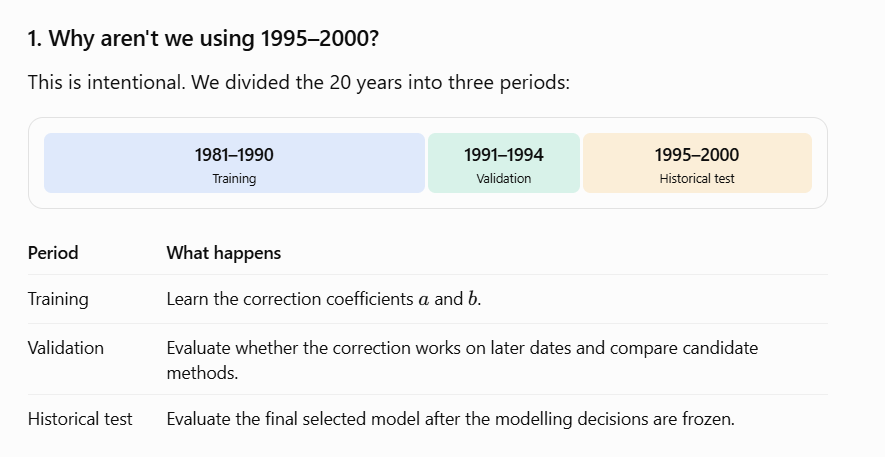

## 6 · Does the correction preserve wet-day skill and monthly totals?

Daily squared-error optimization can lower RMSE while degrading wet-day occurrence or complete-month totals. The lab requires evaluation of rainfall occurrence and monthly totals, so do not claim a correction is universally superior based only on the daily RMSE.

In [23]:
def corrected_wetday_table(pred):
    rows=[]
    for (station,product),p in pred.groupby(['Station','Product']):
        for method,col in [('Raw','Raw_mm_day'),('Linear corrected','Corrected_mm_day')]:
            rows.append({'Station':station,'Product':product,'Method':method,
                         **wetday_scores(p.Gauge_mm_day,p[col])})
    return pd.DataFrame(rows)

validation_corrected_wet=corrected_wetday_table(calibration_predictions)
display(validation_corrected_wet.round(3))
validation_corrected_wet.to_csv(TABDIR/'table09_validation_raw_corrected_wetday.csv',index=False)

def complete_months_of_predictions(p):
    x=p.copy();x['Month']=x.Date.dt.to_period('M').dt.to_timestamp()
    groups=x.groupby(['Station','Product','Month'],as_index=False).agg(
        days=('Date','nunique'), Gauge_month_mm=('Gauge_mm_day','sum'),
        Raw_month_mm=('Raw_mm_day','sum'),Corrected_month_mm=('Corrected_mm_day','sum'))
    return groups[groups.days==groups.Month.dt.days_in_month].copy()

monthly_calibration=complete_months_of_predictions(calibration_predictions)
monthly_rows=[]
for (st,prod),g in monthly_calibration.groupby(['Station','Product']):
    for method,column in [('Raw','Raw_month_mm'),('Linear corrected','Corrected_month_mm')]:
        o=g.Gauge_month_mm.to_numpy();e=g[column].to_numpy()
        monthly_rows.append({'Station':st,'Product':prod,'Method':method,'n_complete_months':len(g),
                             'MAE_mm_month':np.mean(abs(e-o)),
                             'RMSE_mm_month':np.sqrt(np.mean((e-o)**2)),
                             'Bias_mm_month':np.mean(e-o),
                             'Pearson_r':stats.pearsonr(o,e).statistic if len(o)>2 else np.nan})
monthly_calibrated_scores=pd.DataFrame(monthly_rows)
display(monthly_calibrated_scores.round(3))
monthly_calibrated_scores.to_csv(TABDIR/'table10_validation_raw_corrected_monthly.csv',index=False)

,Station,Product,Method,n,threshold_mm_day,Hits,Misses,False_alarms,Correct_negatives,POD,FAR,CSI
0,Badulla,CHIRPS v2,Raw,1461,1.0,236,251,161,813,0.485,0.406,0.364
1,Badulla,CHIRPS v2,Linear corrected,1461,1.0,487,0,974,0,1.000,0.667,0.333
2,Badulla,CHIRPS v3 RNL,Raw,1461,1.0,405,82,348,626,0.832,0.462,0.485
3,Badulla,CHIRPS v3 RNL,Linear corrected,1461,1.0,487,0,974,0,1.000,0.667,0.333
4,Colombo,CHIRPS v2,Raw,1460,1.0,284,266,160,750,0.516,0.360,0.400
5,Colombo,CHIRPS v2,Linear corrected,1460,1.0,550,0,910,0,1.000,0.623,0.377
6,Colombo,CHIRPS v3 RNL,Raw,1460,1.0,489,61,442,468,0.889,0.475,0.493
7,Colombo,CHIRPS v3 RNL,Linear corrected,1460,1.0,550,0,910,0,1.000,0.623,0.377
8,Galle,CHIRPS v2,Raw,1461,1.0,239,379,83,760,0.387,0.258,0.341
9,Galle,CHIRPS v2,Linear corrected,1461,1.0,618,0,843,0,1.000,0.577,0.423


,Station,Product,Method,n_complete_months,MAE_mm_month,RMSE_mm_month,Bias_mm_month,Pearson_r
0,Badulla,CHIRPS v2,Raw,48,52.844,73.860,2.535,0.811
1,Badulla,CHIRPS v2,Linear corrected,48,67.955,84.628,14.529,0.814
2,Badulla,CHIRPS v3 RNL,Raw,48,42.241,60.301,9.755,0.874
3,Badulla,CHIRPS v3 RNL,Linear corrected,48,58.716,72.437,10.807,0.875
4,Colombo,CHIRPS v2,Raw,47,55.378,87.651,-32.780,0.886
5,Colombo,CHIRPS v2,Linear corrected,47,80.013,105.603,-15.632,0.886
6,Colombo,CHIRPS v3 RNL,Raw,47,39.012,66.126,-15.373,0.935
7,Colombo,CHIRPS v3 RNL,Linear corrected,47,52.915,85.696,-25.265,0.935
8,Galle,CHIRPS v2,Raw,48,62.091,98.912,-20.083,0.823
9,Galle,CHIRPS v2,Linear corrected,48,96.022,128.553,-9.243,0.825


## 7 · Descriptive heavy-rainfall analysis (extension)

For a declared gauge threshold of **≥25 mm/day**, compare raw and corrected RMSE on *gauge-defined* heavy days. This is a **conditional retrospective diagnostic**, not an event detector; deciding a day is heavy from the gauge would not be available in a real prediction task. Report the heavy-day sample size because the subsets are small at some stations.

In [25]:
heavy_rows=[]
for (st,prod),p in calibration_predictions.groupby(['Station','Product']):
    h=p[p.Gauge_mm_day>=HEAVY_THRESHOLD_MM]
    for method,col in [('Raw','Raw_mm_day'),('Linear corrected','Corrected_mm_day')]:
        heavy_rows.append({'Station':st,'Product':prod,'Method':method,'n_gauge_heavy_days':len(h),
                           'threshold_mm_day':HEAVY_THRESHOLD_MM,
                           'RMSE_mm_day':np.sqrt(np.mean((h[col]-h.Gauge_mm_day)**2)) if len(h) else np.nan,
                           'Bias_mm_day':np.mean(h[col]-h.Gauge_mm_day) if len(h) else np.nan})
heavy_scores=pd.DataFrame(heavy_rows)
display(heavy_scores.round(3))
heavy_scores.to_csv(TABDIR/'table11_validation_gauge_heavyday_scores.csv',index=False)

,Station,Product,Method,n_gauge_heavy_days,threshold_mm_day,RMSE_mm_day,Bias_mm_day
0,Badulla,CHIRPS v2,Raw,79,25.0,31.810,-22.490
1,Badulla,CHIRPS v2,Linear corrected,79,25.0,34.317,-29.790
2,Badulla,CHIRPS v3 RNL,Raw,79,25.0,33.770,-26.842
3,Badulla,CHIRPS v3 RNL,Linear corrected,79,25.0,35.768,-30.632
4,Colombo,CHIRPS v2,Raw,115,25.0,57.448,-36.638
5,Colombo,CHIRPS v2,Linear corrected,115,25.0,60.799,-40.817
6,Colombo,CHIRPS v3 RNL,Raw,115,25.0,58.750,-34.625
7,Colombo,CHIRPS v3 RNL,Linear corrected,115,25.0,60.901,-38.279
8,Galle,CHIRPS v2,Raw,102,25.0,48.872,-31.506
9,Galle,CHIRPS v2,Linear corrected,102,25.0,53.240,-40.379


## 8 · Sensitivity to trace values

The processed source maps trace observations (`.0T`) to numeric zero. Excluding trace-flagged days and repeating the raw validation summary demonstrates whether that convention materially changes descriptive statistics. **This sensitivity calculation should not retroactively determine the training protocol**, and any changes to QC policy must be justified before rerunning all models.

In [27]:
no_trace = raw[raw.QC_Flag!='Trace'].copy()
trace_sens = score_products(no_trace)
comparison_trace = validation_daily[['Station','Product','n','RMSE_mm_day']].merge(
    trace_sens[['Station','Product','n','RMSE_mm_day']],on=['Station','Product'],suffixes=('_all','_excluding_traces'))
comparison_trace['difference_RMSE_mm_day']=(comparison_trace.RMSE_mm_day_excluding_traces-
                                              comparison_trace.RMSE_mm_day_all)
display(comparison_trace.round(4))
comparison_trace.to_csv(TABDIR/'table12_trace_sensitivity.csv',index=False)

,Station,Product,n_all,RMSE_mm_day_all,n_excluding_traces,RMSE_mm_day_excluding_traces,difference_RMSE_mm_day
0,Badulla,CHIRPS v2,1461,11.3047,1356,11.5426,0.2379
1,Badulla,CHIRPS v3 RNL,1461,10.8199,1356,11.0891,0.2692
2,Colombo,CHIRPS v2,1460,18.5407,1460,18.5407,0.0000
3,Colombo,CHIRPS v3 RNL,1460,17.9575,1460,17.9575,0.0000
4,Galle,CHIRPS v2,1461,17.6086,1461,17.6086,0.0000
5,Galle,CHIRPS v3 RNL,1461,15.8217,1461,15.8217,0.0000
6,Kandy,CHIRPS v2,1461,12.6647,1461,12.6647,0.0000
7,Kandy,CHIRPS v3 RNL,1461,10.5694,1461,10.5694,0.0000
8,Nuwaraeliya,CHIRPS v2,1458,13.4300,1458,13.4300,0.0000
9,Nuwaraeliya,CHIRPS v3 RNL,1458,10.6057,1458,10.6057,0.0000


## 9 · Research interpretation worksheet — complete after running

1. For each station, which version has lower daily RMSE on 1991–1994, and is that consistent with MAE, wet-day CSI and Pearson $r$? If not, explain the trade-off.
2. Can Pearson $r$ be high even when rainfall magnitudes are systematically wrong? Explain using bias/RMSE.
3. Why do we use complete calendar months? How many months per station are valid?
4. Which linear corrections improved **validation** RMSE and which worsened it? Did monthly totals and wet-day skill move in the same direction?
5. What does the trace-sensitivity comparison tell you? Does it resolve ambiguity in the original field records?
6. What physical mechanisms could explain disagreement? **Distinguish plausible explanations from tested causes** (pixel versus gauge, cloud-to-rain conversion, timing mismatch, terrain, within-pentad allocations).
7. Why is the chronological validation independent of *fitted coefficients*, and why is 1995–2000 not an entirely untouched confirmatory test in the overall exploratory project?

**Do not use this notebook to select the final best station model.** We first complete multiscale, rolling-origin and physics-informed experiments, then finalize selections in Final Notebook 06.

## 10 · Literature and source links

**Primary sources**

1. **PH3043 University of Colombo, Project 2:** *Evaluation of CHIRPS Daily Rainfall Estimates at Selected Meteorological Stations in Sri Lanka*. Supplied lab brief. Mandates GEE, date pairing, metrics, wet-day, monthly/seasonal comparison, simple correction and chronological withheld validation.
2. Funk, C. et al. (2015). *The climate hazards infrared precipitation with stations—a new environmental record for monitoring extremes*. **Scientific Data 2**, 150066. https://doi.org/10.1038/sdata.2015.66
3. Funk, C. et al. (2026). *The Climate Hazards Center Infrared Precipitation with Stations, Version 3*. **Scientific Data**. https://doi.org/10.1038/s41597-026-07096-4 — details ERA5-based daily disaggregation of pentad totals, which we will examine later.
4. Google Earth Engine CHIRPS v2 catalogue: https://developers.google.com/earth-engine/datasets/catalog/UCSB-CHG_CHIRPS_DAILY
5. Google Earth Engine CHIRPS v3 RNL catalogue: https://developers.google.com/earth-engine/datasets/catalog/UCSB-CHC_CHIRPS_V3_DAILY_RNL
6. Hyndman, R. J. & Athanasopoulos, G. *Forecasting: Principles and Practice*, 3rd ed., https://otexts.com/fpp3/ — chronological and rolling-origin model evaluation (introduced in a later notebook).

**Interpretation caution:** CHIRPS incorporates station observations into its dataset construction, so a gauge not used during *our calibration* is not necessarily independent of the original CHIRPS product. No claim of complete satellite–gauge independence is made.

**Reproduction:** Source dataset is read-only; tables saved to `results/Final_01_Lab_Validation/run_###/tables/`, figures to `/figures/`. Notebook source and underlying GEE extraction scripts should be committed alongside the dataset metadata and README.

The simple linear calibration was fitted using observations from 1981–1990 and evaluated on independent chronological validation dates from 1991–1994. Although the correction reduced daily RMSE at five of the six stations for CHIRPS v3 RNL, further evaluation revealed important limitations. Positive model intercepts increased predicted wet-day frequency and false alarms, while accumulation of daily corrected estimates increased monthly-total RMSE at all six stations. These findings demonstrate that improvements in daily error statistics do not necessarily translate into improved rainfall occurrence or accumulated rainfall accuracy. Consequently, subsequent experiments will investigate rainfall occurrence–intensity models and independent calibration at daily and monthly timescale